
$Designing\ Gausiian\ Filter\ for\ Gaussian\ Noise$

$ G(x,y)= (\frac{1}{2 * \pi * (\sigma)^{2}})^{\frac{-(x^{2}+y^{2})}{2 * \sigma^{2}}} $

$ Where\ G(x,y)\ is\ position\ of\ the\ kernel\ elements $



(np.float64(-0.5), np.float64(601.5), np.float64(338.5), np.float64(-0.5))

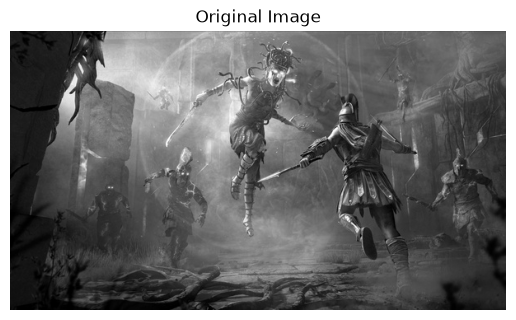

In [2]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

#Original image read
image = cv2.imread('image.jpg', cv2.IMREAD_GRAYSCALE)
plt.imshow(image, cmap='gray')
plt.title("Original Image")
plt.axis('off')

(np.float64(-0.5), np.float64(601.5), np.float64(338.5), np.float64(-0.5))

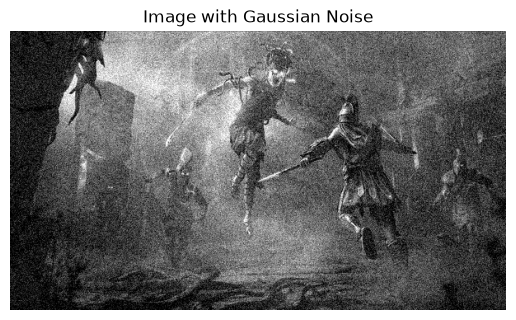

In [3]:
#Adding Gaussian noise to the image
def add_gaussian_noise(image,mean=0,sigma=25):
    noise = np.random.normal(mean,sigma,image.shape)
    noisy_image = image.astype(np.float32) + noise

    noisy_image = np.clip(noisy_image,0,255)
    return noisy_image.astype(np.uint8)

noisy_image = add_gaussian_noise(image,mean=0,sigma=25)
plt.imshow(noisy_image , cmap='gray')
plt.title("Image with Gaussian Noise")
plt.axis('off')


(np.float64(-0.5), np.float64(601.5), np.float64(338.5), np.float64(-0.5))

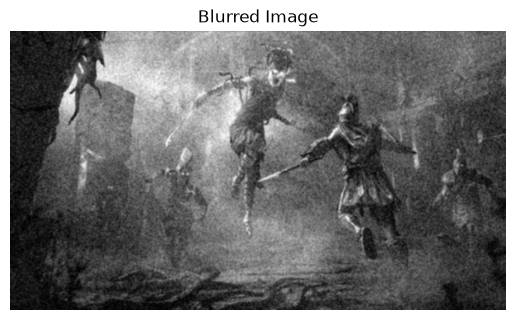

In [4]:
kernel = 1 /16 * np.array([[1, 2, 1], [2, 4, 2], [1, 2, 1]])
blurred_image = cv2.filter2D(noisy_image, -1, kernel)
plt.imshow(blurred_image, cmap='gray')
plt.title('Blurred Image')
plt.axis('off')

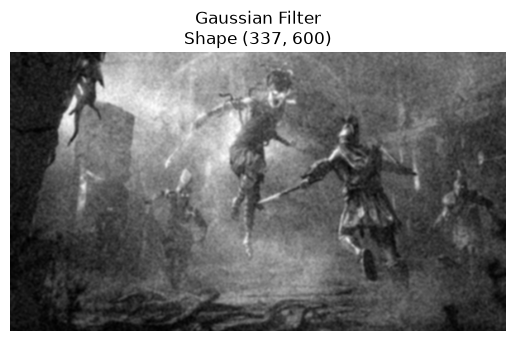

In [6]:
def gaussian_filter(image, kernel_size=3, sigma=1):
    
    # Create Gaussian kernel
    k = kernel_size // 2
    x, y = np.meshgrid(
        np.arange(-k, k + 1),
        np.arange(-k, k + 1)
    )

    kernel = np.exp(-(x**2 + y**2) / (2 * sigma**2))
    kernel = kernel / np.sum(kernel)

    # Output image
    h, w = image.shape
    output = np.zeros((h - kernel_size + 1, w - kernel_size + 1))

    # Apply filter
    for i in range(h - kernel_size + 1):
        for j in range(w - kernel_size + 1):

            region = image[
                i:i + kernel_size,
                j:j + kernel_size
            ]

            output[i, j] = np.sum(region * kernel)

    return output.astype(np.uint8)


denoised_image = gaussian_filter(
    blurred_image,
    kernel_size=3,
    sigma=25
)

# Display
plt.imshow(denoised_image, cmap='gray')
plt.title(f'Gaussian Filter\nShape {denoised_image.shape}')
plt.axis('off')
plt.show()